In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [43]:
df=pd.read_csv('economic_index.csv')

In [44]:
df.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [45]:
df.corr()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
Unnamed: 0,1.000000,-8.667781e-01,-4.986939e-01,-0.934555,0.935300,-0.988246
year,-0.866778,1.000000e+00,7.884865e-14,0.882851,-0.877000,0.863232
month,-0.498694,7.884865e-14,1.000000e+00,0.339526,-0.351189,0.481287
interest_rate,-0.934555,8.828507e-01,3.395257e-01,1.000000,-0.925814,0.935793
unemployment_rate,0.935300,-8.769997e-01,-3.511891e-01,-0.925814,1.000000,-0.922338
index_price,-0.988246,8.632321e-01,4.812873e-01,0.935793,-0.922338,1.000000


In [46]:
df.drop(columns=['Unnamed: 0','year','month'],axis=1,inplace=True)

In [47]:
df

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256
5,2.50,5.6,1254
6,2.50,5.5,1234
7,2.25,5.5,1195
8,2.25,5.5,1159
9,2.25,5.6,1167


In [48]:
df.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


In [49]:
df.isnull().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

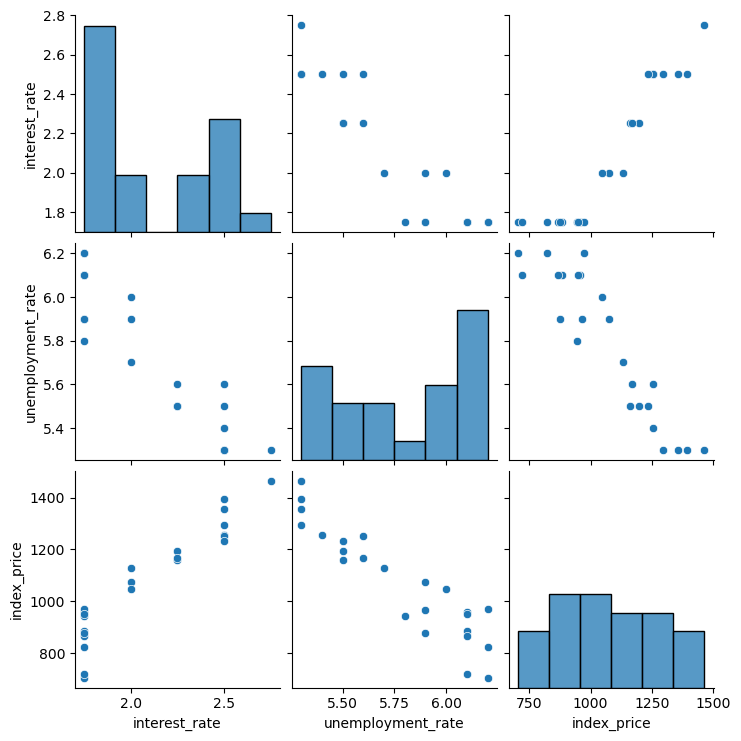

In [50]:
sns.pairplot(df)

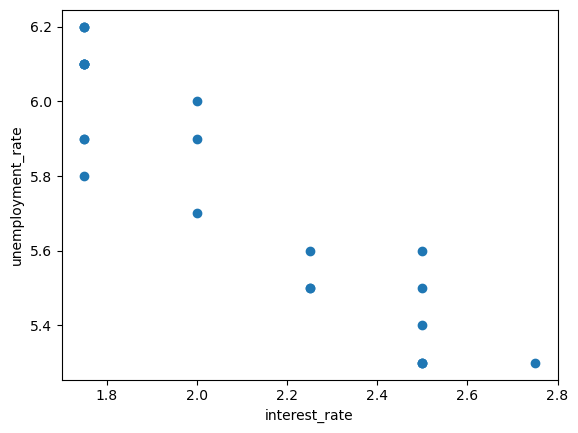

In [51]:
plt.scatter(df['interest_rate'],df['unemployment_rate'])
plt.xlabel('interest_rate')
plt.ylabel('unemployment_rate')
plt.show()

In [52]:
#defining independent and dependent features
X=df[['interest_rate','unemployment_rate']]
y=df['index_price']

In [53]:
X

,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4
5,2.50,5.6
6,2.50,5.5
7,2.25,5.5
8,2.25,5.5
9,2.25,5.6


In [54]:
y

0     1464
1     1394
2     1357
3     1293
4     1256
5     1254
6     1234
7     1195
8     1159
9     1167
10    1130
11    1075
12    1047
13     965
14     943
15     958
16     971
17     949
18     884
19     866
20     876
21     822
22     704
23     719
Name: index_price, dtype: int64

In [55]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,       # Proportion (or exact count) of samples reserved for testing
    random_state=42,     # Seed for reproducible shuffling before splitting      
)

In [56]:
from sklearn.preprocessing import StandardScaler

In [57]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler to standardize features to mean = 0 and standard deviation = 1:
# z = (x - mu) / sigma
# Note: StandardScaler is sensitive to outliers and assumes roughly bell-shaped features.
scaler = StandardScaler()

# FIT on X_train ONLY to learn training mean (mu) and std (sigma), then TRANSFORM X_train.
# Never fit on X_test—doing so leaks test-set distribution info into training (data leakage).
X_train_scaled = scaler.fit_transform(X_train)

# TRANSFORM X_test using the training mean and std learned above so evaluation mirrors
# unseen real-world inference (where test/production data arrives one sample/batch at a time).
X_test_scaled = scaler.transform(X_test)

In [58]:
X_train_scaled

array([[-0.90115511,  0.37908503],
       [ 1.31077107, -1.48187786],
       [-0.90115511,  1.30956648],
       [ 1.31077107, -0.55139641],
       [ 1.31077107, -1.48187786],
       [-0.16384638,  0.68924552],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -1.48187786],
       [ 1.31077107, -1.17171738],
       [-0.90115511,  1.30956648],
       [-0.90115511,  0.999406  ],
       [-0.90115511,  0.37908503],
       [-0.90115511,  0.999406  ],
       [ 0.57346234, -0.8615569 ],
       [-0.16384638, -0.24123593],
       [-0.90115511,  0.06892455],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -0.8615569 ]])

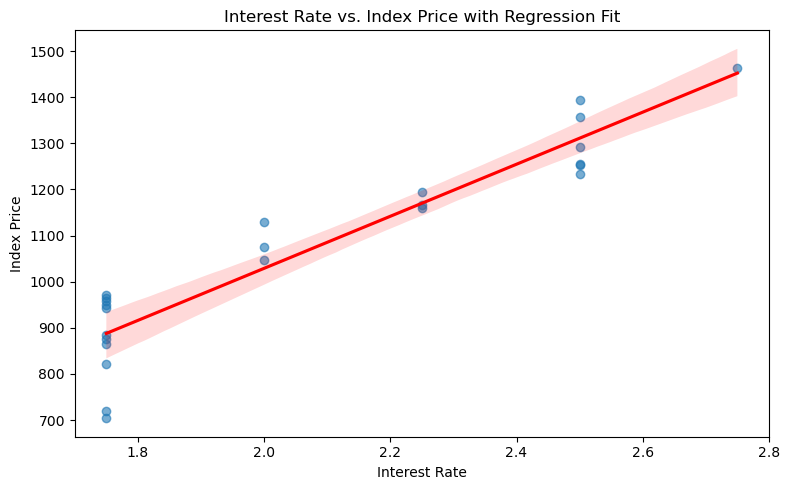

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure so plot sizing and labels stay clean in the notebook
plt.figure(figsize=(8, 5))

# Plot a scatter plot of two numeric columns along with a fitted linear regression line
# and a 95% confidence interval band (shaded region) around the fit.
# Pass x and y as keyword arguments (required in Seaborn v0.12+).
sns.regplot(
    data=df,
    x="interest_rate", # Predictor (x-axis)
    y="index_price",   # Target/response (y-axis)
    scatter_kws={"alpha": 0.6},  # Make scatter points semi-transparent to spot overlap
    line_kws={"color": "red"}    # Highlight the fitted trend line
)

plt.title("Interest Rate vs. Index Price with Regression Fit")
plt.xlabel("Interest Rate")
plt.ylabel("Index Price")
plt.tight_layout()
plt.show()

In [60]:
from sklearn.linear_model import LinearRegression

In [61]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [62]:
print(model.intercept_)

1053.4444444444443


In [63]:
print(model.coef_)

[  88.27275507 -116.25716066]


In [64]:
y_pred = model.predict(X_test_scaled)

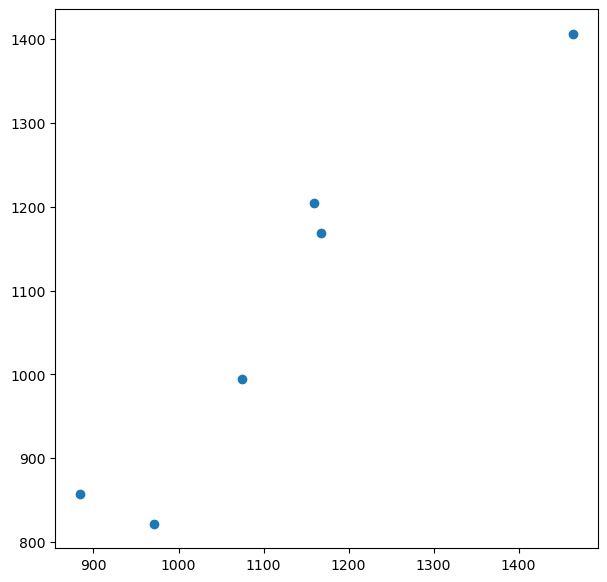

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred)
plt.show()

In [77]:
residual=y_test-y_pred

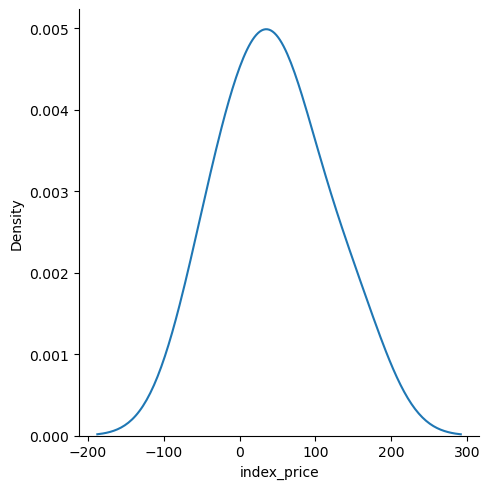

In [78]:
sns.displot(residual,kind='kde')

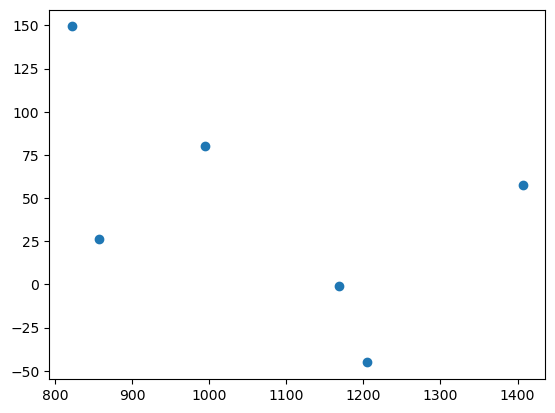

In [79]:
plt.scatter(y_pred,residual)

In [33]:
from sklearn.model_selection import cross_val_score

In [37]:
scores = cross_val_score(model, X, y, cv=5,scoring='r2')
print(scores)

[ 0.56590849 -0.25461029  0.14743258 -5.98513309 -4.05485945]


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [39]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

In [81]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -----------------

In [82]:
import statsmodels.api as sm
model=sm.OLS(y_train,X_train).fit()

In [84]:
model.summary()

e:\anaconda\envs\abdullah\Lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=18 observations were given.
  return hypotest_fun_in(*args, **kwds)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:            index_price   R-squared (uncentered):                   0.995
Model:                            OLS   Adj. R-squared (uncentered):              0.994
Method:                 Least Squares   F-statistic:                              1468.
Date:                Wed, 25 Nov 2026   Prob (F-statistic):                    7.46e-19
Time:                        14:11:32   Log-Likelihood:                         -104.21
No. Observations:                  18   AIC:                                      212.4
Df Residuals:                      16   BIC:                                      214.2
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
interest_rate       569.9494     44.349     12.851      0.000     475.933     663.965
unemployment_rate   -20.5734     15.966     -1.289      0.216     -54.421      13.274
==============================================================================
Omnibus:                        1.657   Durbin-Watson:                   1.707
Prob(Omnibus):                  0.437   Jarque-Bera (JB):                1.346
Skew:                          -0.611   Prob(JB):                        0.510
Kurtosis:                       2.451   Cond. No.                         14.6
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""